# Comedy Show: learn decisions with a tree

Original tutorial: [W3Schools: Decision Tree](https://www.w3schools.com/python/python_ml_decision_tree.asp).

Use `Pandas` and `Scikit-Learn` to create a Decision Tree classifier to predict whether an audience will attend a comedy show. This small example makes the learned rules easy to inspect.

### Topics
- Load a CSV table
- Encode categories and a binary target
- Train and visualize a Decision Tree
- Compare predictions for two comedians

**Question for the lesson:** Which features guide the decision to go to a show?

> **Estimated time: 60 min**

## 1 · Import the tools

Pandas loads the table. We import scikit-learn and Matplotlib to train and draw the tree.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

## 2 · Load and inspect the table

Open `data.csv` from the same folder as this notebook. Each row describes a comedian and whether the audience decided to go to the show (`Go`).

In [2]:
df = pd.read_csv("data.csv")
df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


## 3 · Convert categories into numbers

Encode `Nationality` as `UK = 0`, `USA = 1`, and `N = 2`. Encode the target as `YES = 1` and `NO = 0`. These nationality codes are labels; their numerical order does not represent a ranking.

In [3]:
d = {'UK': 0, 'USA': 1, 'N': 2}
df['Nationality'] = df['Nationality'].map(d)
d = {'YES': 1, 'NO': 0}
df['Go'] = df['Go'].map(d)

df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
5,44,14,5,0,0
6,66,3,7,2,1
7,35,14,9,0,1
8,52,13,7,2,1
9,35,5,9,2,1


## 4 · Choose features and target

`X` contains age, experience, rank, and nationality. `y` contains the attendance decision to predict. Keep this feature order when supplying new rows.

In [4]:
features = ['Age', 'Experience', 'Rank', 'Nationality']

X = df[features]
y = df['Go']

display(X)
display(y)

,Age,Experience,Rank,Nationality
0,36,10,9,0
1,42,12,4,1
2,23,4,6,2
3,52,4,4,1
4,43,21,8,1
5,44,14,5,0
6,66,3,7,2
7,35,14,9,0
8,52,13,7,2
9,35,5,9,2


0     0
1     0
2     0
3     0
4     1
5     0
6     1
7     1
8     1
9     1
10    0
11    1
12    1
Name: Go, dtype: int64

## 5 · Train and visualize the Decision Tree

A classifier learns if/then rules that separate the two target classes. The code fits the tree on every row, then draws its splits. Follow a path from the root to a leaf: `samples` counts training rows, `value` counts rows in each class, and lower Gini impurity means a purer node.

There is no held-out test set here, so the diagram demonstrates learned rules rather than measured performance on unseen data.

[Text(0.2857142857142857, 0.9, 'Rank <= 6.5\ngini = 0.497\nsamples = 13\nvalue = [6, 7]'),
 Text(0.14285714285714285, 0.7, 'gini = 0.0\nsamples = 5\nvalue = [5, 0]'),
 Text(0.21428571428571427, 0.8, 'True  '),
 Text(0.42857142857142855, 0.7, 'Rank <= 8.5\ngini = 0.219\nsamples = 8\nvalue = [1, 7]'),
 Text(0.3571428571428571, 0.8, '  False'),
 Text(0.2857142857142857, 0.5, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.5714285714285714, 0.5, 'Experience <= 9.5\ngini = 0.375\nsamples = 4\nvalue = [1, 3]'),
 Text(0.42857142857142855, 0.3, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.7142857142857143, 0.3, 'Age <= 35.5\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.5714285714285714, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.8571428571428571, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]')]

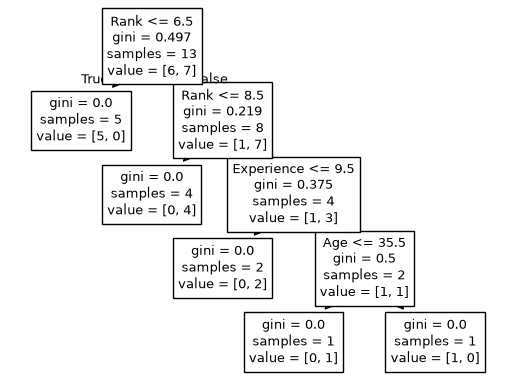

In [5]:
dtree = DecisionTreeClassifier()
dtree = dtree.fit(X, y)

tree.plot_tree(dtree, feature_names=features)

In [6]:
importances = dtree.feature_importances_
importances

array([0.1547619 , 0.07738095, 0.76785714, 0.        ])

## 6 · Predict

In [7]:
sample = pd.DataFrame([{
    'Age': 40,
    'Experience': 10,
    'Rank': 7,
    'Nationality': 1,
}])

print(dtree.predict(sample))

[1]


## Key takeaways

- Decision Trees turn feature values into a sequence of decisions.
- Encode text categories and preserve the feature order at prediction time.
- Small changes in an input can move a sample to a different leaf.
- Use a separate test set before making claims about predictive accuracy.